> STATUS: ATUAL — execução final COM, BEST época 3.
> Revisão editorial em 30/10/2026: somente apresentação de resultados existentes; este notebook não foi reexecutado nesta revisão.
> Consulte o [guia oficial](../../../GUIA_NOTEBOOKS_RESULTADOS.md). Os notebooks 03/04 contêm chamadas de inferência; seus outputs estão preservados e não devem ser reexecutados nesta etapa editorial.


In [1]:
# [celula injetada pelo executor] redireciona config para a politica shared-extrasystoles-bbb-v1
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config
config.CLASSIFICATION_POLICY = "shared-extrasystoles-bbb-v1"
config.MITBIH_PROCESSED_FILE = config.PROCESSED_DIR / "mitbih_shared-extrasystoles-bbb-v1.npz"
config.LUDB_PROCESSED_FILE = config.PROCESSED_DIR / "ludb_shared-extrasystoles-bbb-v1.npz"


# 05 — Grad-CAM 1D + anotações clínicas

Carrega o Grad-CAM **já extraído** por `src/extract_gradcam.py`
(`ludb_gradcam.npz` — mapas de todos os 390 batimentos do LUDB, prontos, sem
rodar o modelo aqui) e as **anotações clínicas** de P, QRS e T do dataset
processado do LUDB (`src/preprocess_ludb.py`), e plota os dois juntos: a
própria linha do ECG colorida pela ativação do Grad-CAM (`LineCollection`),
com as regiões anotadas sombreadas atrás do sinal.

Isto é uma demonstração visual do Grad-CAM lado a lado com o *ground truth*
fisiológico, não a métrica de fidelidade da Etapa 4 — aqui olhamos os dois
apenas por inspeção, sem ainda reduzir a comparação a um número.

Os artefatos desta execução já estão presentes no pacote. Não é necessário executar o pipeline para consultar estes outputs; veja o guia oficial.

## 1. Carregando os dados pré-computados

Nenhum modelo é carregado neste notebook — a extração (cara, precisa de
forward+backward) já foi feita uma vez pelo script; aqui só lemos os arrays
salvos (barato, é só `np.load`). É a separação que `extract_gradcam.py`
existe para viabilizar: extrair uma vez, visualizar/analisar quantas vezes
quiser.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import sys
from pathlib import Path

# O codigo do projeto vive em src/ (nao ha pacote instalavel).
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config
import beat_io
''
RUN_DIR = config.MODELS_DIR / "cnn1d_mitbih_shared-extrasystoles-bbb-v1"
GRADCAM_FILE = RUN_DIR / "gradcam_ludb" / "ludb_gradcam.npz"

gcam = np.load(GRADCAM_FILE, allow_pickle=True)
cam_interp = gcam["cam_interp"]  # (n, 234) — mapa já reamostrado para a janela do batimento
y_true = gcam["y_true"]
y_pred = gcam["y_pred"]
y_score = gcam["y_score"]
ritmos = gcam["ritmos"]
limiar = float(gcam["threshold"])

# Sinal e anotações clínicas: mesmo dataset, mesma ordem de índice usada por
# extract_gradcam.py — nenhum embaralhamento em nenhum passo do pipeline.
ludb = beat_io.load_beat_dataset(config.LUDB_PROCESSED_FILE)
X = ludb["series"]
regiao_p = ludb["regiao_p"]
regiao_qrs = ludb["regiao_qrs"]
regiao_t = ludb["regiao_t"]

assert X.shape[0] == cam_interp.shape[0]
print(f"{X.shape[0]} batimentos | cam_interp {cam_interp.shape} | limiar {limiar:.2f}")

390 batimentos | cam_interp (390, 234) | limiar 0.50


## 2. Plotando o batimento com Grad-CAM e anotações clínicas

Duas camadas de informação sobre o mesmo eixo de tempo:

- a própria linha do ECG muda de cor ponto a ponto conforme o valor do
  Grad-CAM naquele instante — um `LineCollection` do Matplotlib, que desenha
  cada segmento entre dois pontos consecutivos com sua própria cor;
- as regiões de P, QRS e T anotadas pelos especialistas (`regiao_p/qrs/t`, o
  onset/offset de cada onda **deste** batimento) ficam sombreadas atrás do
  sinal, cada uma numa cor fixa distinta das cores do Grad-CAM.

É a comparação lado a lado entre "onde o modelo olhou" e "onde a
eletrofisiologia realmente está".

In [3]:
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Patch

tempo = (np.arange(X.shape[1]) - config.WINDOW_LEFT) / config.TARGET_FS * 1000

CORES_ONDA = {"P": "#27ae60", "QRS": "#7f8c8d", "T": "#8e44ad"}
REGIOES = {"P": regiao_p, "QRS": regiao_qrs, "T": regiao_t}


def desenha_gradcam(idx, eixo):
    """Desenha o batimento `idx` (ECG + Grad-CAM + anotações) no eixo dado.

    Retorna o `LineCollection`, para quem chamou decidir se quer uma colorbar
    própria (`mostra_gradcam`) ou uma única colorbar compartilhada
    (`mostra_quadrantes`).
    """
    batimento = X[idx]
    mapa = cam_interp[idx]

    # Anotações clínicas primeiro, como fundo: axvspan de onset a offset de
    # cada onda. Sentinela (-1, -1) (onda ausente) simplesmente não é desenhada.
    presentes = []
    for nome, regioes_onda in REGIOES.items():
        onset, offset = regioes_onda[idx]
        if onset < 0:
            continue
        eixo.axvspan(tempo[onset], tempo[offset], color=CORES_ONDA[nome], alpha=0.18)
        presentes.append(nome)

    # Um segmento de reta entre cada par de pontos consecutivos (tempo[i], batimento[i])
    # -> (tempo[i+1], batimento[i+1]); cada segmento recebe a cor do Grad-CAM
    # no seu ponto inicial.
    pontos = np.column_stack([tempo, batimento]).reshape(-1, 1, 2)
    segmentos = np.concatenate([pontos[:-1], pontos[1:]], axis=1)

    linhas = LineCollection(
        segmentos, cmap="jet", norm=Normalize(vmin=0, vmax=1), linewidths=2.2
    )
    linhas.set_array(mapa[:-1])
    eixo.add_collection(linhas)

    eixo.set_xlim(tempo[0], tempo[-1])
    margem = 0.1 * (batimento.max() - batimento.min())
    eixo.set_ylim(batimento.min() - margem, batimento.max() + margem)
    eixo.set_xlabel("ms em relação ao pico R")
    eixo.set_ylabel("amplitude (z-score)")

    legenda_ondas = [
        Patch(facecolor=CORES_ONDA[nome], alpha=0.4, label=nome) for nome in presentes
    ]
    if legenda_ondas:
        eixo.legend(handles=legenda_ondas, loc="upper right", fontsize=7, title="anotação clínica")

    real = "arritmia" if y_true[idx] else "normal"
    previsto = "arritmia" if y_pred[idx] else "normal"
    ausentes = [nome for nome in REGIOES if nome not in presentes]
    nota_ausencia = f" | sem {'/'.join(ausentes)}" if ausentes else ""
    eixo.set_title(
        f"batimento {idx} | ritmo: {ritmos[idx]} | real: {real} | "
        f"previsto: {previsto} (score {y_score[idx]:.3f}){nota_ausencia}",
        fontsize=9,
    )
    return linhas


def mostra_gradcam(idx):
    """Plota um único batimento em figura própria, com sua colorbar."""
    fig, eixo = plt.subplots(figsize=(9, 3.5))
    linhas = desenha_gradcam(idx, eixo)
    fig.colorbar(linhas, ax=eixo, label="ativação Grad-CAM (normalizada)")
    fig.tight_layout()
    plt.show()

## 3. Os quatro casos da matriz de confusão

Verdadeiro positivo, verdadeiro negativo, falso positivo e falso negativo —
cada um é o batimento **mais confiante** daquele quadrante (maior ou menor
score, conforme o caso), para pegar o exemplo mais nítido de cada situação:

| Quadrante | Real | Previsto | O que procurar no mapa |
| --- | --- | --- | --- |
| VP | arritmia | arritmia | vermelho dentro do QRS/T — acerto por motivo certo? |
| VN | normal | normal | pouca ativação em qualquer lugar (ver nota abaixo) |
| FP | normal | arritmia | vermelho em ruído/artefato, ou em estrutura real? |
| FN | arritmia | normal | havia sinal no lugar certo, só que fraco demais? |

**Nota sobre o VN**: o Grad-CAM é sempre calculado em relação à saída da
classe arritmia (nunca da classe prevista). Num
verdadeiro negativo isso é esperado dar uma ativação fraca por toda a janela;
como o mapa é normalizado pelo próprio máximo de cada batimento
(`cam / cam.max()`), mesmo essa ativação fraca aparece com um pico "vermelho"
em algum ponto — o que não deve ser lido como "a rede reconheceu estruturas
relevantes", e sim como ruído de gradiente amplificado pela normalização
local. É por isso que a Etapa 4 vai precisar registrar também a magnitude
*bruta* do pico, não só o mapa normalizado.

In [4]:
def indice_mais_confiante(mask, y_score, maximizar):
    candidatos = np.flatnonzero(mask)
    if candidatos.size == 0:
        return None  # quadrante vazio (ex.: nenhum falso positivo)
    escolha = np.argmax if maximizar else np.argmin
    return candidatos[escolha(y_score[candidatos])]


quadrantes = {
    "VP": indice_mais_confiante((y_true == 1) & (y_pred == 1), y_score, maximizar=True),
    "VN": indice_mais_confiante((y_true == 0) & (y_pred == 0), y_score, maximizar=False),
    "FP": indice_mais_confiante((y_true == 0) & (y_pred == 1), y_score, maximizar=True),
    "FN": indice_mais_confiante((y_true == 1) & (y_pred == 0), y_score, maximizar=False),
}
for nome, idx in quadrantes.items():
    if idx is None:
        print(f"{nome}: nenhum batimento neste quadrante")
    else:
        print(f"{nome}: batimento {idx} (score {y_score[idx]:.3f})")

VP: batimento 130 (score 1.000)
VN: batimento 373 (score 0.000)
FP: batimento 327 (score 0.610)
FN: batimento 267 (score 0.000)


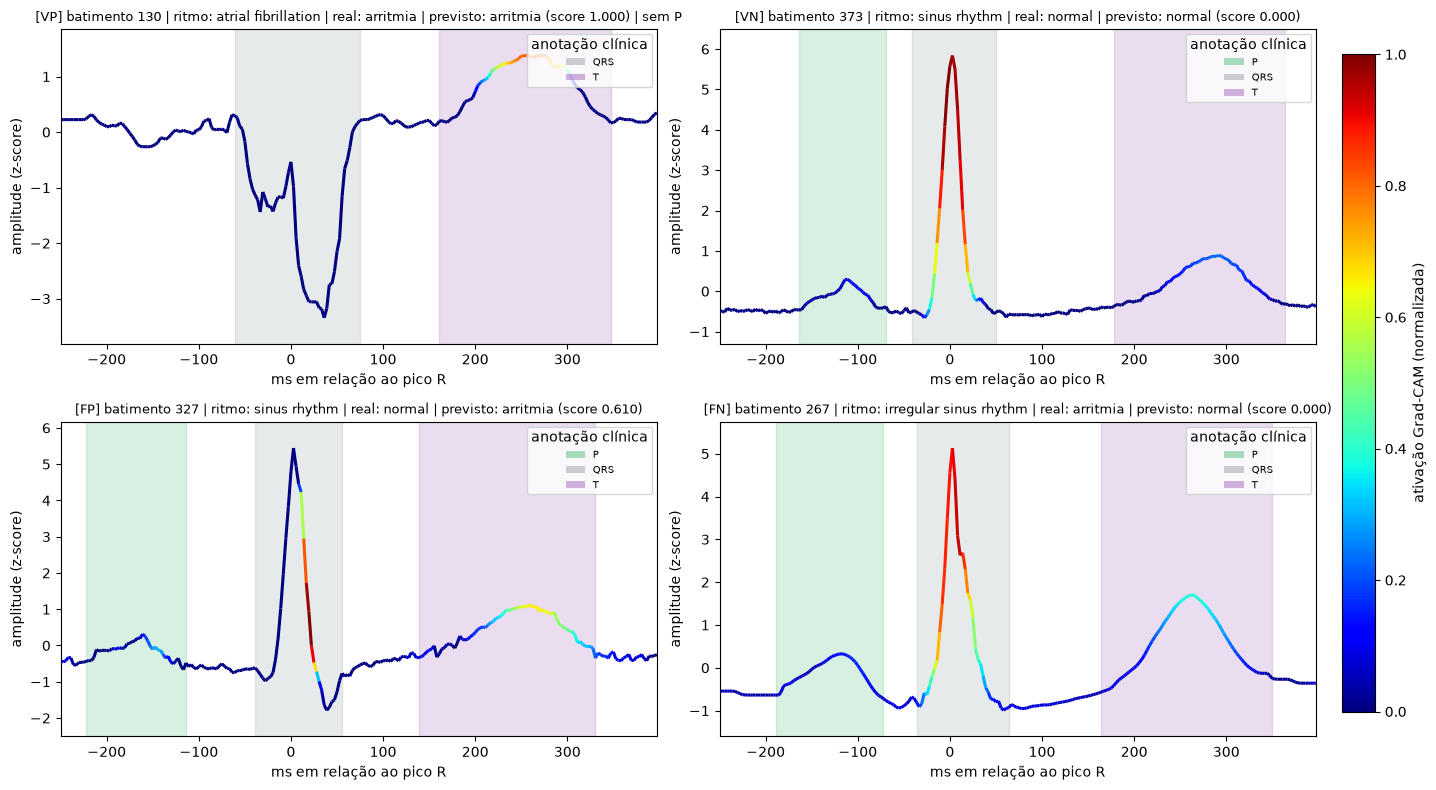

In [5]:
def mostra_quadrantes(quadrantes):
    fig, eixos = plt.subplots(2, 2, figsize=(15, 8))
    linhas = None
    for eixo, (nome, idx) in zip(eixos.ravel(), quadrantes.items()):
        if idx is None:
            eixo.axis("off")
            eixo.set_title(f"[{nome}] nenhum batimento neste quadrante", fontsize=9)
            continue
        linhas = desenha_gradcam(idx, eixo)
        eixo.set_title(f"[{nome}] {eixo.get_title()}", fontsize=9)
    fig.tight_layout(rect=[0, 0, 0.93, 1])
    fig.colorbar(
        linhas, ax=eixos, label="ativação Grad-CAM (normalizada)",
        fraction=0.025, pad=0.02,
    )
    plt.show()


mostra_quadrantes(quadrantes)

## 4. Próximo passo

Troque qualquer índice em `quadrantes`, ou chame `mostra_gradcam(i)` direto
para um único batimento — funciona para qualquer `i` entre 0 e
`X.shape[0] - 1`, instantâneo porque `cam_interp` já está todo pré-computado
em memória.

Isto ainda é comparação **visual**: o gráfico usa `regiao_p/qrs/t` (onset e
offset das ondas deste batimento) só para desenhar as faixas. A Etapa 4
formaliza a mesma ideia em número, cruzando `cam_interp` diretamente com
`ludb["mascara_clinica"]` — a máscara booleana `(n, 234)` que já une P, QRS e T
amostra a amostra — pelo IoU entre o mapa binarizado e a máscara clínica (sem medir fração de energia). Como discutido para o quadrante VN acima, essa
métrica deve vir acompanhada da magnitude bruta do pico de ativação, para não
confundir "ativação fraca e ruidosa" com "ativação bem localizada".